# Simulación del problema bancario
Este notebook compara varias distribuciones de cajeros para retiros y pagos. Los comentarios en el código explican brevemente qué hace cada parte.

In [10]:
# Importamos las librerías que usamos para calcular, organizar y graficar los datos.
# Definimos una jornada de 8 horas, 10 réplicas y una semilla para repetir los resultados.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

HORIZON = 8 * 60
N_REPLICAS = 10
SEED = 20261120

datos = {
    "Retiro": {
        "Rápido": {"p": 0.23, "servicio": 1, "llegada": 1},
        "Normal": {"p": 0.40, "servicio": 2, "llegada": 2},
        "Lento": {"p": 0.17, "servicio": 3, "llegada": 3},
        "Muy lento": {"p": 0.20, "servicio": 4, "llegada": 3},
    },
    "Pago": {
        "Rápido": {"p": 0.10, "servicio": 3, "llegada": 1},
        "Normal": {"p": 0.20, "servicio": 3, "llegada": 2},
        "Lento": {"p": 0.30, "servicio": 5, "llegada": 3},
        "Muy lento": {"p": 0.40, "servicio": 7, "llegada": 4},
    }
}
CONFIGURACIONES = {
    "3 cajas mixtas": {"Mixta": 3},
    "1 retiro + 2 pagos": {"Retiro": 1, "Pago": 2},
    "2 retiros + 1 pago": {"Retiro": 2, "Pago": 1},
    "2 retiros + 2 pagos (4 cajas)": {"Retiro": 2, "Pago": 2},
}

# Esta función simula la llegada y atención de los usuarios durante una jornada.
def simular_replica(semilla, cajas, horizonte=HORIZON):
    rng = np.random.default_rng(semilla)
    disponibilidad = {op: [0.0] * n for op, n in cajas.items()}
    registros = []
    reloj = 0.0

    # Generamos usuarios hasta que se cumplan los 480 minutos de atención.
    while True:
        accion = rng.choice(["Retiro", "Pago"], p=[0.70, 0.30])
        subtipos = list(datos[accion])
        probabilidades = [datos[accion][t]["p"] for t in subtipos]
        tipo = rng.choice(subtipos, p=probabilidades)

        reloj += rng.exponential(datos[accion][tipo]["llegada"])
        if reloj > horizonte:
            break

        # Una caja mixta atiende ambas operaciones; las especializadas solo su operación.
        grupo_cajas = "Mixta" if "Mixta" in cajas else accion
        indice = int(rng.integers(len(disponibilidad[grupo_cajas])))
        cajero = f"{grupo_cajas}-{indice + 1}"

        # Calculamos cuánto espera el usuario y cuánto dura su atención.
        servicio = rng.exponential(datos[accion][tipo]["servicio"])
        inicio = max(reloj, disponibilidad[grupo_cajas][indice])
        espera = inicio - reloj
        fin = inicio + servicio
        disponibilidad[grupo_cajas][indice] = fin

        registros.append({
            "llegada_min": reloj, "accion": accion, "tipo_usuario": tipo,
            "cajero": cajero, "servicio_min": servicio,
            "inicio_servicio_min": inicio, "fin_servicio_min": fin,
            "espera_min": espera, "tiempo_sistema_min": espera + servicio
        })

    df = pd.DataFrame(registros)
    utilizaciones = {}
    for grupo, servidores in disponibilidad.items():
        for i in range(len(servidores)):
            cajero = f"{grupo}-{i + 1}"
            trabajos = df[df["cajero"] == cajero]
            ocupado = 0.0
            for fila in trabajos.itertuples():
                ocupado += max(0.0, min(fila.fin_servicio_min, horizonte) - fila.inicio_servicio_min)
            utilizaciones[cajero] = ocupado / horizonte
    return df, utilizaciones

# Ejecutamos las 10 réplicas para cada configuración de cajeros.
eventos = []
utilizaciones = []
for indice_config, (nombre, cajas) in enumerate(CONFIGURACIONES.items()):
    for replica in range(1, N_REPLICAS + 1):
        df, uso = simular_replica(SEED + indice_config * 1000 + replica, cajas)
        df["configuracion"] = nombre
        df["replica"] = replica
        eventos.append(df)
        for cajero, utilizacion in uso.items():
            utilizaciones.append({
                "configuracion": nombre, "replica": replica,
                "cajero": cajero, "utilizacion_observada": utilizacion
            })

# Unimos todos los registros para realizar el análisis.
datos_simulados = pd.concat(eventos, ignore_index=True)
utilizacion_df = pd.DataFrame(utilizaciones)
print("Simulación terminada.")
print(f"Configuraciones: {len(CONFIGURACIONES)} | Réplicas por configuración: {N_REPLICAS}")
print(f"Duración de cada réplica: {HORIZON} minutos")
print(f"Total de eventos de llegada registrados: {len(datos_simulados)}")

Simulación terminada.
Configuraciones: 4 | Réplicas por configuración: 10
Duración de cada réplica: 480 minutos
Total de eventos de llegada registrados: 7941


In [11]:
# Calculamos el resumen de cada configuración y el intervalo de confianza de la espera.
# Al final mostramos las configuraciones ordenadas por tiempo promedio de espera.
def intervalo_confianza_95(valores):
    valores = pd.Series(valores).dropna()
    if len(valores) < 2:
        return np.nan, np.nan
    margen = 1.96 * valores.std(ddof=1) / np.sqrt(len(valores))
    return valores.mean() - margen, valores.mean() + margen

resumen = []
for nombre, grupo in datos_simulados.groupby("configuracion"):
    diarios = grupo.groupby("replica").agg(
        espera=("espera_min", "mean"),
        servicio=("servicio_min", "mean"),
        sistema=("tiempo_sistema_min", "mean")
    )
    inf, sup = intervalo_confianza_95(diarios["espera"])
    uso_diario = utilizacion_df[utilizacion_df.configuracion == nombre].groupby("replica").utilizacion_observada.mean()
    resumen.append({
        "configuracion": nombre,
        "usuarios_10_jornadas": len(grupo),
        "usuarios_promedio_jornada": len(grupo) / N_REPLICAS,
        "espera_media_min": grupo.espera_min.mean(),
        "espera_IC95_inferior": inf,
        "espera_IC95_superior": sup,
        "servicio_medio_min": grupo.servicio_min.mean(),
        "tiempo_sistema_medio_min": grupo.tiempo_sistema_min.mean(),
        "utilizacion_media_cajas": uso_diario.mean(),
        "utilizacion_maxima_caja": utilizacion_df[utilizacion_df.configuracion == nombre].groupby("cajero").utilizacion_observada.mean().max()
    })
resumen_df = pd.DataFrame(resumen).sort_values("espera_media_min")
display(resumen_df)

,configuracion,usuarios_10_jornadas,usuarios_promedio_jornada,espera_media_min,espera_IC95_inferior,espera_IC95_superior,servicio_medio_min,tiempo_sistema_medio_min,utilizacion_media_cajas,utilizacion_maxima_caja
2,2 retiros + 2 pagos (4 cajas),1979,197.9,1.573711,1.243025,1.878720,3.122813,4.696523,0.319143,0.344733
1,2 retiros + 1 pago,2048,204.8,3.437105,2.271901,4.522261,3.158888,6.595992,0.436872,0.606851
3,3 cajas mixtas,1961,196.1,3.657936,2.965257,4.272716,3.276515,6.934451,0.437314,0.481968
0,1 retiro + 2 pagos,1953,195.3,5.181631,3.244921,7.217250,3.182091,8.363722,0.423627,0.663021


In [12]:
# Separamos los resultados entre retiros y pagos para comparar sus tiempos.
por_operacion = (datos_simulados.groupby(["configuracion", "accion"])
    .agg(usuarios=("accion", "size"),
         espera_media_min=("espera_min", "mean"),
         servicio_medio_min=("servicio_min", "mean"),
         tiempo_sistema_medio_min=("tiempo_sistema_min", "mean"))
    .reset_index())
display(por_operacion)

,configuracion,accion,usuarios,espera_media_min,servicio_medio_min,tiempo_sistema_medio_min
0,1 retiro + 2 pagos,Pago,605,1.837368,4.890558,6.727927
1,1 retiro + 2 pagos,Retiro,1348,6.682579,2.415309,9.097888
2,2 retiros + 1 pago,Pago,604,7.785702,5.094823,12.880524
3,2 retiros + 1 pago,Retiro,1444,1.618162,2.349120,3.967282
4,2 retiros + 2 pagos (4 cajas),Pago,598,1.774890,4.864160,6.639050
5,2 retiros + 2 pagos (4 cajas),Retiro,1381,1.486596,2.368775,3.855371
6,3 cajas mixtas,Pago,596,3.266683,5.456524,8.723207
7,3 cajas mixtas,Retiro,1365,3.828769,2.324658,6.153426


In [13]:
# Contamos los usuarios de cada tipo y calculamos su promedio por jornada.
promedios_tipo = (datos_simulados.groupby(["configuracion", "accion", "tipo_usuario"])
    .size().rename("usuarios_10_jornadas").reset_index())
promedios_tipo["promedio_diario"] = promedios_tipo["usuarios_10_jornadas"] / N_REPLICAS
display(promedios_tipo.sort_values(["configuracion", "accion", "tipo_usuario"]))

,configuracion,accion,tipo_usuario,usuarios_10_jornadas,promedio_diario
0,1 retiro + 2 pagos,Pago,Lento,177,17.7
1,1 retiro + 2 pagos,Pago,Muy lento,233,23.3
2,1 retiro + 2 pagos,Pago,Normal,135,13.5
3,1 retiro + 2 pagos,Pago,Rápido,60,6.0
4,1 retiro + 2 pagos,Retiro,Lento,228,22.8
5,1 retiro + 2 pagos,Retiro,Muy lento,299,29.9
6,1 retiro + 2 pagos,Retiro,Normal,526,52.6
7,1 retiro + 2 pagos,Retiro,Rápido,295,29.5
8,2 retiros + 1 pago,Pago,Lento,183,18.3
9,2 retiros + 1 pago,Pago,Muy lento,243,24.3


In [14]:
# Mostramos cuántos usuarios de cada tipo llegaron en cada réplica.
totales_replica = (datos_simulados.groupby(["configuracion", "replica", "accion", "tipo_usuario"])
    .size().rename("cantidad_usuarios").reset_index())
display(totales_replica)

,configuracion,replica,accion,tipo_usuario,cantidad_usuarios
0,1 retiro + 2 pagos,1,Pago,Lento,18
1,1 retiro + 2 pagos,1,Pago,Muy lento,22
2,1 retiro + 2 pagos,1,Pago,Normal,19
3,1 retiro + 2 pagos,1,Pago,Rápido,2
4,1 retiro + 2 pagos,1,Retiro,Lento,12
...,...,...,...,...,...
315,3 cajas mixtas,10,Pago,Rápido,5
316,3 cajas mixtas,10,Retiro,Lento,16
317,3 cajas mixtas,10,Retiro,Muy lento,32
318,3 cajas mixtas,10,Retiro,Normal,55


In [15]:
# Calculamos las estadísticas de cada cajero: usuarios, servicio, espera y utilización.
# Después estimamos las medidas de referencia del modelo M/M/1.
estadisticas_cajero = (datos_simulados.groupby(["configuracion", "cajero"])
    .agg(usuarios=("cajero", "size"),
         servicio_promedio_min=("servicio_min", "mean"),
         espera_promedio_min=("espera_min", "mean"),
         tiempo_sistema_promedio_min=("tiempo_sistema_min", "mean"))
    .reset_index()
    .merge(utilizacion_df.groupby(["configuracion", "cajero"]).utilizacion_observada.mean().reset_index(),
           on=["configuracion", "cajero"], how="left"))
display(estadisticas_cajero)

referencia_mm1 = []
for (config, cajero), grupo in datos_simulados.groupby(["configuracion", "cajero"]):
    tasa_llegada = len(grupo) / (N_REPLICAS * HORIZON)
    tasa_servicio = 1 / grupo.servicio_min.mean()
    rho = tasa_llegada / tasa_servicio
    estable = rho < 1
    if estable:
        L = rho / (1-rho)
        Lq = rho**2 / (1-rho)
        W = 1 / (tasa_servicio-tasa_llegada)
        Wq = rho / (tasa_servicio-tasa_llegada)
    else:
        L = Lq = W = Wq = np.nan
    referencia_mm1.append({
        "configuracion": config, "cajero": cajero,
        "lambda_clientes_min": tasa_llegada, "mu_clientes_min": tasa_servicio,
        "rho_aprox": rho, "estable_aprox": estable,
        "L_aprox": L, "Lq_aprox": Lq, "W_aprox_min": W, "Wq_aprox_min": Wq
    })
referencia_mm1_df = pd.DataFrame(referencia_mm1)
display(referencia_mm1_df)

,configuracion,cajero,usuarios,servicio_promedio_min,espera_promedio_min,tiempo_sistema_promedio_min,utilizacion_observada
0,1 retiro + 2 pagos,Pago-1,310,4.680251,1.564267,6.244518,0.301227
1,1 retiro + 2 pagos,Pago-2,295,5.111560,2.124356,7.235915,0.306635
2,1 retiro + 2 pagos,Retiro-1,1348,2.415309,6.682579,9.097888,0.663021
3,2 retiros + 1 pago,Pago-1,604,5.094823,7.785702,12.880524,0.606851
4,2 retiros + 1 pago,Retiro-1,745,2.368006,1.492458,3.860465,0.367179
5,2 retiros + 1 pago,Retiro-2,699,2.328991,1.752139,4.081130,0.336586
6,2 retiros + 2 pagos (4 cajas),Pago-1,288,4.909564,2.003135,6.912699,0.293978
7,2 retiros + 2 pagos (4 cajas),Pago-2,310,4.821979,1.562842,6.384821,0.306470
8,2 retiros + 2 pagos (4 cajas),Retiro-1,688,2.329138,1.623245,3.952383,0.331393
9,2 retiros + 2 pagos (4 cajas),Retiro-2,693,2.408127,1.350933,3.759060,0.344733


,configuracion,cajero,lambda_clientes_min,mu_clientes_min,rho_aprox,estable_aprox,L_aprox,Lq_aprox,W_aprox_min,Wq_aprox_min
0,1 retiro + 2 pagos,Pago-1,0.064583,0.213664,0.302266,True,0.433211,0.130945,6.707789,2.027538
1,1 retiro + 2 pagos,Pago-2,0.061458,0.195635,0.314148,True,0.458040,0.143892,7.452860,2.341301
2,1 retiro + 2 pagos,Retiro-1,0.280833,0.414026,0.678299,True,2.108479,1.430180,7.507937,5.092628
3,2 retiros + 1 pago,Pago-1,0.125833,0.196278,0.641099,True,1.786280,1.145181,14.195601,9.100779
4,2 retiros + 1 pago,Retiro-1,0.155208,0.422296,0.367534,True,0.581113,0.213579,3.744087,1.376080
5,2 retiros + 1 pago,Retiro-2,0.145625,0.429370,0.339159,True,0.513224,0.174065,3.524285,1.195294
6,2 retiros + 2 pagos (4 cajas),Pago-1,0.060000,0.203684,0.294574,True,0.417583,0.123009,6.959714,2.050150
7,2 retiros + 2 pagos (4 cajas),Pago-2,0.064583,0.207384,0.311419,True,0.452263,0.140843,7.002781,2.180802
8,2 retiros + 2 pagos (4 cajas),Retiro-1,0.143333,0.429343,0.333843,True,0.501148,0.167305,3.496380,1.167243
9,2 retiros + 2 pagos (4 cajas),Retiro-2,0.144375,0.415261,0.347673,True,0.532974,0.185301,3.691596,1.283469


In [16]:
# Comparamos las dos alternativas que tienen tres cajas.
# Identificamos cuál registró menos llegadas para cada tipo de usuario.
comparacion_3_cajas = promedios_tipo[promedios_tipo.configuracion.isin(
    ["1 retiro + 2 pagos", "2 retiros + 1 pago"])]
indices_minimos = comparacion_3_cajas.groupby(["accion", "tipo_usuario"])["promedio_diario"].idxmin()
minimos_por_tipo = comparacion_3_cajas.loc[indices_minimos].sort_values(["accion", "tipo_usuario"])
display(minimos_por_tipo)

,configuracion,accion,tipo_usuario,usuarios_10_jornadas,promedio_diario
0,1 retiro + 2 pagos,Pago,Lento,177,17.7
1,1 retiro + 2 pagos,Pago,Muy lento,233,23.3
10,2 retiros + 1 pago,Pago,Normal,116,11.6
3,1 retiro + 2 pagos,Pago,Rápido,60,6.0
12,2 retiros + 1 pago,Retiro,Lento,225,22.5
13,2 retiros + 1 pago,Retiro,Muy lento,296,29.6
6,1 retiro + 2 pagos,Retiro,Normal,526,52.6
7,1 retiro + 2 pagos,Retiro,Rápido,295,29.5


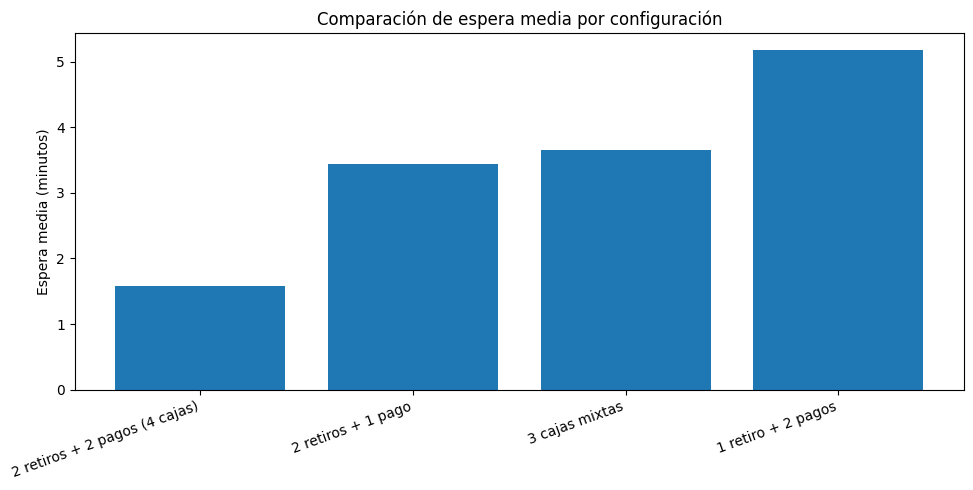

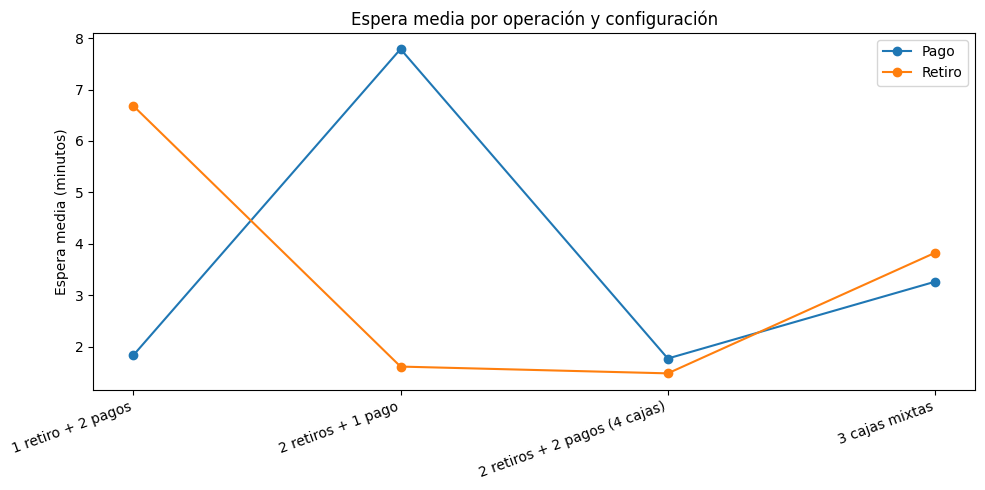

In [17]:
# Graficamos la espera promedio total y la espera separada por operación.
plt.figure(figsize=(10,5))
plt.bar(resumen_df.configuracion, resumen_df.espera_media_min)
plt.ylabel("Espera media (minutos)")
plt.title("Comparación de espera media por configuración")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,5))
for accion, grupo in por_operacion.groupby("accion"):
    plt.plot(grupo.configuracion, grupo.espera_media_min, marker="o", label=accion)
plt.ylabel("Espera media (minutos)")
plt.title("Espera media por operación y configuración")
plt.xticks(rotation=20, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
# Guardamos las tablas de resultados en un archivo de Excel, cada una en una hoja.
archivo_excel = "Resultados_Simulacion_Colas_Banco_CORREGIDO.xlsx"
with pd.ExcelWriter(archivo_excel, engine="openpyxl") as writer:
    resumen_df.to_excel(writer, sheet_name="Resumen", index=False)
    por_operacion.to_excel(writer, sheet_name="Por_operacion", index=False)
    promedios_tipo.to_excel(writer, sheet_name="Promedios_por_tipo", index=False)
    totales_replica.to_excel(writer, sheet_name="Detalle_replicas", index=False)
    estadisticas_cajero.to_excel(writer, sheet_name="Estadisticas_cajero", index=False)
    referencia_mm1_df.to_excel(writer, sheet_name="M_M_1_referencia", index=False)
    minimos_por_tipo.to_excel(writer, sheet_name="Minimos_por_tipo", index=False)
    datos_simulados.to_excel(writer, sheet_name="Eventos", index=False)
print(f"Archivo generado: {archivo_excel}")

Archivo generado: Resultados_Simulacion_Colas_Banco_CORREGIDO.xlsx


In [20]:
# Descargamos el archivo de Excel generado en la celda anterior.
from google.colab import files
import os

archivo = "Resultados_Simulacion_Colas_Banco_CORREGIDO.xlsx"

if os.path.exists(archivo):
    files.download(archivo)
else:
    print("No se encontró el archivo. Ejecuta primero la celda de exportación.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>